Task 1: Basic K-Means Clustering

Description: In this task, you will generate a synthetic dataset and apply the K-Means clustering algorithm to group data points into a specified number of clusters. This will help understand how K-Means works by identifying central points (centroids) and assigning data points to the nearest centroid.

C:\Users\sreet\AppData\Local\Temp\ipykernel_26580\2577925879.py:10: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[:, 0], X[:, 1], s=50, cmap='viridis')


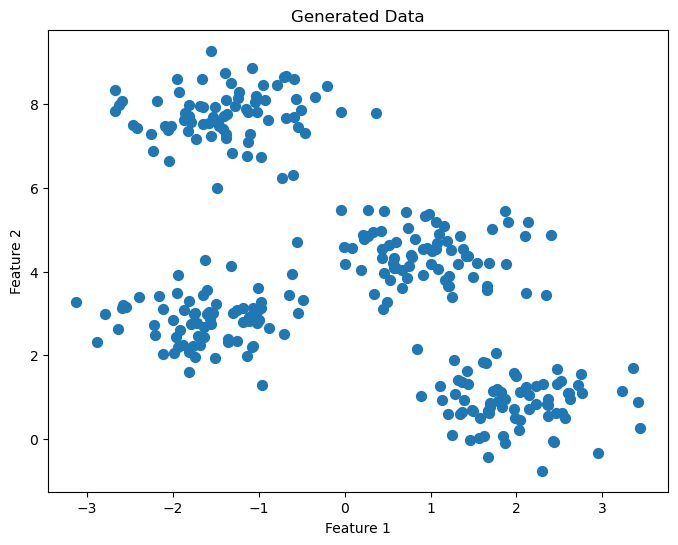

C:\Users\sreet\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


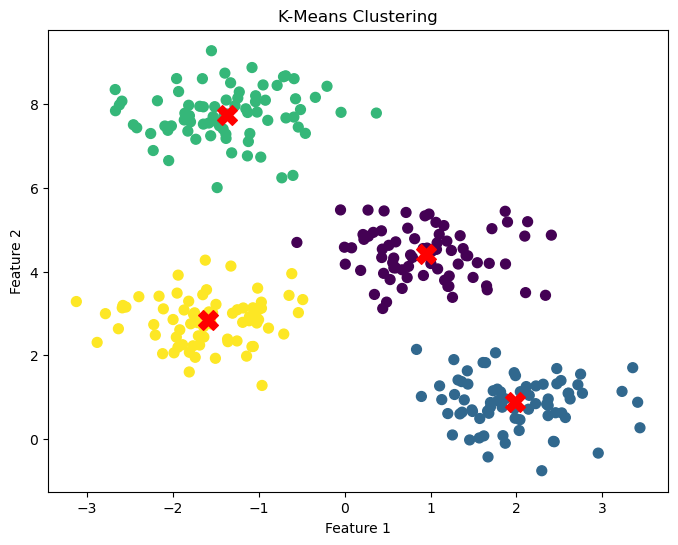

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate synthetic data
X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

# Visualize the generated data (optional, to see the true clusters)
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50, cmap='viridis')
plt.title("Generated Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 2. Apply K-Means clustering
k_means = KMeans(n_clusters=4, init='k-means++', max_iter=300, random_state=0, n_init=10)
y_kmeans = k_means.fit_predict(X)

# 3. Visualize the clusters and centroids
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
plt.scatter(k_means.cluster_centers_[:, 0], k_means.cluster_centers_[:, 1],
            s=200, c='red', marker='X', label='Centroids')
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend
plt.show()

Task 2: Exploring the Elbow Method for Optimal K

Description: Determining the optimal number of clusters (K) is a crucial step in K-Means. This task will guide you through using the Elbow Method, a heuristic approach, to find a suitable K by plotting the Within-Cluster Sum of Squares (WCSS) against the number of clusters. You will observe where the decrease in WCSS begins to slow down significantly, resembling an “elbow” in the plot.

In [5]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

C:\Users\sreet\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\sreet\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\sreet\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\sreet\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

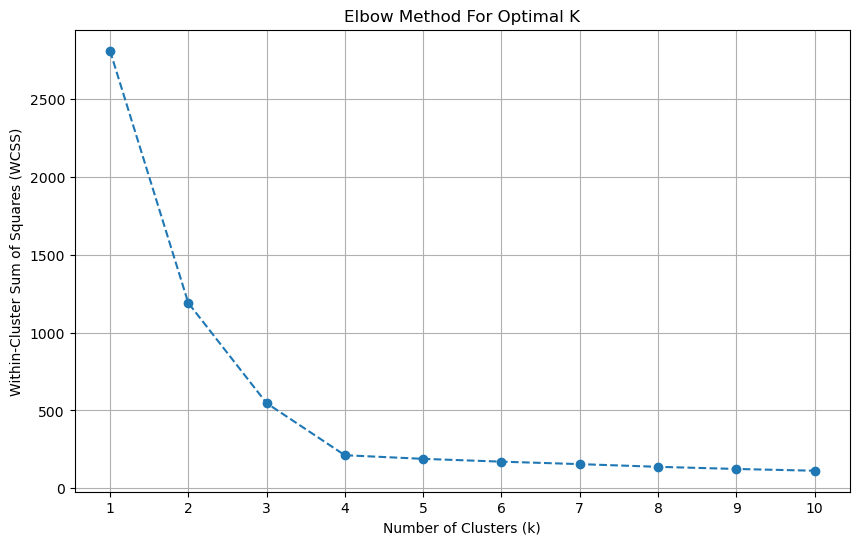

In [6]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Re-generate the same synthetic data for consistency
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

WCSS = []
max_k = 10  # Let's test k from 1 to 10

for i in range(1, max_k + 1):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, random_state=0, n_init=10)
    kmeans.fit(X)
    WCSS.append(kmeans.inertia_)  # inertia_ is the WCSS

# Plotting the Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, max_k + 1), WCSS, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(range(1, max_k + 1))
plt.grid(True)
plt.show()

Task 3: Exploring Agglomerative Hierarchical Clustering
Description: Agglomerative Hierarchical Clustering is a bottom-up clustering technique used to group similar data points into clusters. This task will guide you through creating a dendrogram using the Ward linkage method to visualize the hierarchical relationships between data points. You will then apply Agglomerative Clustering to divide the given dataset into two clusters and visualize the results using a scatter plot.

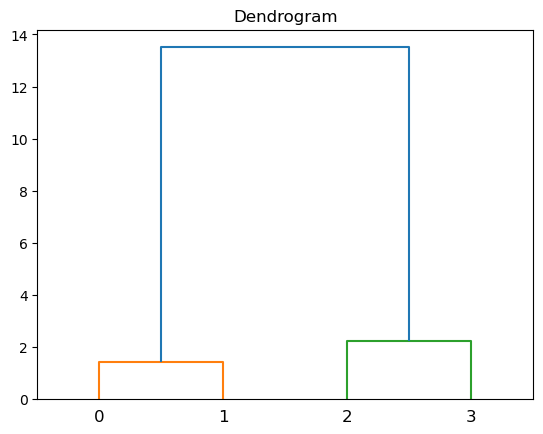

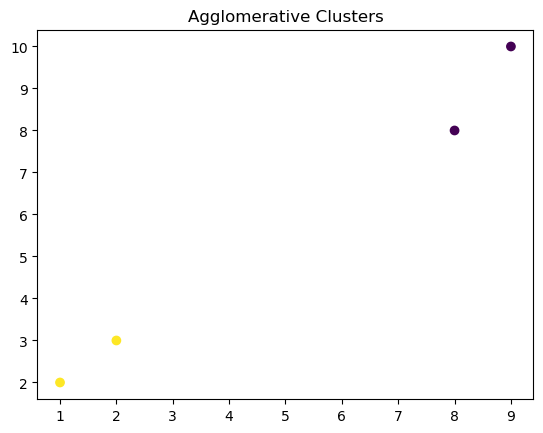

In [8]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

X = [[1, 2], [2, 3], [8, 8], [9, 10]]

# Diagram 1: Dendrogram
linked = linkage(X, method="ward")
plt.figure()
dendrogram(linked)
plt.title("Dendrogram")
plt.show()

# Divide into 2 clusters
model = AgglomerativeClustering(n_clusters=2, linkage="ward")
labels = model.fit_predict(X)

# Diagram 2: Clusters
plt.figure()
plt.scatter([p[0] for p in X], [p[1] for p in X], c=labels)
plt.title("Agglomerative Clusters")
plt.show()